# Swift scene capacity

The marble block is drawn in Swift as many small cubes, so the size of a cube depends on how many objects the scene can hold. Here we measure the time of a simulation step with the robot, the table and the block in three cases (the scene standing still, the block turning with the table, cubes being removed).

The timings depend on the machine and the browser. They were measured on an Intel Core i7-14700HX with 16 GB of RAM, Windows 11 and Firefox.

## Setup

In [1]:
# Imports

import logging
import time
import warnings

# A few docstrings in the toolbox trigger SyntaxWarnings when Python compiles them; not related to our code
warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import roboticstoolbox as rtb
import spatialgeometry as sg
import spatialmath as sm
import swift

from sculptor.scene import RECORDINGS, fix_mesh_paths, recording, show_gif

# Closing a Swift window leaves a few websocket tasks pending; asyncio reports them when they are
# cleaned up, but they are harmless, so we keep them out of the outputs
logging.getLogger("asyncio").setLevel(logging.CRITICAL)

# Without this, Swift on Windows cannot load any mesh (see sculptor/scene.py)
fix_mesh_paths()

# The Swift recordings are saved in results/recordings/; True records them again
RECORD = False

## Block and table

Each cube is stored once, in the frame of the block. The block sits on the table top and turns with it by an angle $\varphi$, so a point of the block is in the world at

$$\mathbf{p}^W = \mathbf{T}^W_T\,\mathbf{R}_z(\varphi)\,\mathbf{p}^B$$

In [2]:
# Initializations
T_table = sm.SE3(0.75, 0.0, 0.2)   # This should be the center of the table-top (where the marble block sits)
BLOCK_SIDE = 0.3                  # [m] width and depth of the block (for now, could change)
BLOCK_HEIGHT = 0.45               # [m]
MARBLE = [0.92, 0.92, 0.88, 1.00]

In [3]:
# Block
def make_blocks(size: float) -> list[np.ndarray]:
    """Centers of the cuboid in the block frame (origin at the center of the bottom face)"""
    n = round(BLOCK_SIDE / size) 
    m = round(BLOCK_HEIGHT / size)
    centers = []
    
    for i in range(n):
        for j in range(n):
            for k in range(m):
                centers.append(np.array([(i - (n - 1) / 2) * size, 
                                         (j - (n - 1) / 2) * size, 
                                         (k - (n - 0.5) / 2) * size]))
    return centers

# Table (where the block goes)
def place(cubes: list[sg.Cuboid], centers: list[np.ndarray], phi: float) -> None:
    """Same block pose for all cubes, then each one at its own place inside the block"""
    T_block = T_table * sm.SE3.Rz(phi)
    for cube, p in zip(cubes, centers):
        cube.T = T_block * sm.SE3(p)

## Scene test

`test_scene` builds the scene for one cube size and returns the time to add the block and the mean time of a step in the three cases. Swift runs as fast as it can (`realtime=False`), so the step time is the cost of the update itself.

In [4]:
# Test
def test_scene(size: float, n_steps: int = 100, dt: float = 0.05) -> dict[str, float]:
    env = swift.Swift()
    env.launch(realtime=False, browser=None)    # Not realtime in this case because we are measuring a single step's speed.
    
    panda = rtb.models.Panda()
    panda.q = panda.qr
    env.add(panda)
    env.add(sg.Cylinder(radius=0.22, length=0.2, pose=sm.SE3(0.75, 0, 0.1), color=[0.4, 0.3, 0.2, 1.0]))
    
    # Chisel held by the "gripper", along the z axis of the hand
    chisel = sg.Cylinder(radius=0.008, length=0.15, color=[0.3, 0.3, 0.3, 1.0])
    chisel.T = panda.fkine(panda.q) * sm.SE3(0, 0, 0.03)
    env.add(chisel)
    
    centers = make_blocks(size)
    cubes = [sg.Cuboid(scale=[size] * 3, color=MARBLE) for _ in centers]
    place(cubes, centers, 0.0)
    
    t0 = time.perf_counter()
    ids = [env.add(cube) for cube in cubes]
    t_add = time.perf_counter() - t0
    
    def mean_step_time(rotate: bool, remove: bool) -> float:
        times = []
        phi = 0.0
        for _ in range(n_steps):
            if rotate:
                phi += 0.02
                place(cubes, centers, phi)
            if remove and cubes:
                env.remove(ids.pop())
                cubes.pop()
                centers.pop()
            t0 = time.perf_counter()
            env.step(dt)
            times.append(time.perf_counter() - t0)
        return float(np.mean(times))
    
    result = {
        "cubes": len(cubes),
        "add [s]": t_add,
        "step, still [s]": mean_step_time(rotate=False, remove=False),
        "step, rotating [s]": mean_step_time(rotate=True, remove=False),
        "step, removing [s]": mean_step_time(rotate=False, remove=True),
    }
    env.close()
    return result

## Cube size

In [5]:
# From large to small cubes
sizes = [0.05, 0.03, 0.02]
results = {size: test_scene(size) for size in sizes}

print(f"{'size [m]':>9} {'cubes':>6} {'add [s]':>8} {'still [s]':>10} {'rotating [s]':>13} {'removing [s]':>13}")
for size, r in results.items():
    print(f"{size:>9} {r['cubes']:>6} {r['add [s]']:>8.2f} {r['step, still [s]']:>10.4f} "
          f"{r['step, rotating [s]']:>13.4f} {r['step, removing [s]']:>13.4f}")

 size [m]  cubes  add [s]  still [s]  rotating [s]  removing [s]
     0.05    324     0.66     0.0008        0.0034        0.0012
     0.03   1500     6.52     0.0085        0.0182        0.0191
     0.02   4950    49.84     0.0397        0.0512        0.0556


With the medium cubes the slowest step takes 0.0191 s (removing cubes), well under the 0.05 s of simulated time that each step stands for, so a replay can run in real time. With the small cubes a step takes 0.0512 s while turning the block and 0.0556 s while removing cubes, longer than the step itself, so a replay would fall behind.

We use cubes of 0.03 m. Adding the block (`add [s]`) happens once at the start, so it does not weigh in the choice.

## Recording

The scene of the test with the medium cubes, recorded once. The block turns with the table for a quarter of a turn, and then cubes are removed one by one by their id.


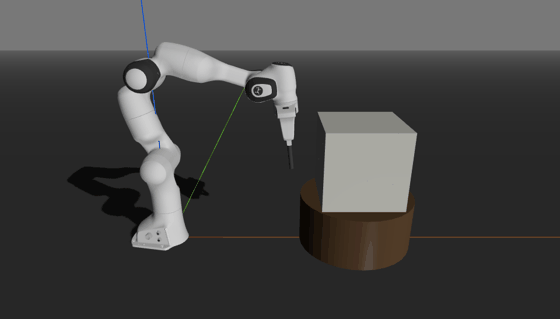

In [6]:
GIF = RECORDINGS / "00_swift_prototype_removing.gif"

# Recorded the first time, or again when RECORD is True; in real time, so the GIF plays at the speed of the simulation
if RECORD or not GIF.exists():
    size, dt = 0.03, 0.05
    env = swift.Swift()
    env.launch(realtime=True, browser=None)
    panda = rtb.models.Panda()
    panda.q = panda.qr
    env.add(panda)
    env.add(sg.Cylinder(radius=0.22, length=0.2, pose=sm.SE3(0.75, 0, 0.1), color=[0.4, 0.3, 0.2, 1.0]))
    chisel = sg.Cylinder(radius=0.008, length=0.15, color=[0.3, 0.3, 0.3, 1.0])
    chisel.T = panda.fkine(panda.q) * sm.SE3(0, 0, 0.03)
    env.add(chisel)

    centers = make_blocks(size)
    cubes = [sg.Cuboid(scale=[size] * 3, color=MARBLE) for _ in centers]
    place(cubes, centers, 0.0)
    ids = [env.add(cube) for cube in cubes]
    env.step(dt)

    with recording(env, GIF):
        for k in range(40):
            place(cubes, centers, np.pi / 2 * (k + 1) / 40)
            env.step(dt)
        for _ in range(60):
            env.remove(ids.pop())
            env.step(dt)
    env.close()

show_gif(GIF)

## Summary

The next notebooks use cubes of 0.03 m (section Cube size), defined once as `CUBE_SIZE` in `src/sculptor/model.py`. Swift is set up with `fix_mesh_paths` from `src/sculptor/scene.py` before anything is added, and cubes are removed by the id that `env.add` returns, so Swift does not search its list of objects at every removal.

In section Cube size the step time grows with the number of cubes in the three cases. With the medium cubes, turning the block takes longer than standing still (0.0182 s against 0.0085 s), because every cube gets a new pose. This is why the table turns only between sectors. Leaving out the inside of the statue, which is never visible, is optional (`drop_interior` in `src/sculptor/model.py`).